# Chapitre 4 - Cours 3 : Avro, schéma de l'écrivain et schéma du lecteur

Apache Avro est né en 2009 comme sous-projet de Hadoop, parce que les formats à numéros de
champ ne convenaient pas bien à ses usages. Il pousse l'idée du schéma jusqu'au bout : les
données encodées ne contiennent **ni noms, ni numéros, ni types**, seulement des valeurs
concaténées. L'évolution repose alors sur une **résolution** explicite entre le schéma
avec lequel la donnée a été écrite et celui qu'attend le lecteur. Ce cours couvre la
section *Avro* (*The writer's schema and the reader's schema*, *Schema evolution rules*,
*But what is the writer's schema?*, *Dynamically generated schemas*, *Code generation and dynamically typed languages*) et la
section *The Merits of Schemas*.

**Plan.**

1. Un schéma sans numéros : 32 octets.
2. Schéma de l'écrivain, schéma du lecteur et résolution.
3. Les règles d'évolution, testées.
4. Mais quel est le schéma de l'écrivain ? Fichiers, registres, connexions.
5. Des schémas générés dynamiquement.
6. Les mérites des schémas : bilan comparatif des formats.

In [1]:
import copy
import gzip
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.encoding import PbField, PbMessage
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
R = E.EXAMPLE_RECORD
W = E.PERSON_AVRO

## 1. Un schéma sans numéros (section *Avro*)

Avro a deux langages de schéma : Avro IDL, pour les humains, et une représentation JSON,
plus facile à traiter par programme. Notre enregistrement s'écrit, en IDL :

```
record Person {
    string               userName;
    union { null, long } favoriteNumber = null;
    array<string>        interests;
}
```

et en JSON (c'est la forme que manipule notre module, `E.PERSON_AVRO`) :

In [2]:
print(json.dumps(W, indent=2))

{
  "type": "record",
  "name": "Person",
  "fields": [
    {
      "name": "userName",
      "type": "string"
    },
    {
      "name": "favoriteNumber",
      "type": [
        "null",
        "long"
      ],
      "default": null
    },
    {
      "name": "interests",
      "type": {
        "type": "array",
        "items": "string"
      }
    }
  ]
}


Pas de numéro de champ. Le champ `favoriteNumber` est une **union** de `null` et `long`
avec `null` pour valeur par défaut : c'est ainsi qu'Avro exprime « facultatif ». Encodons.

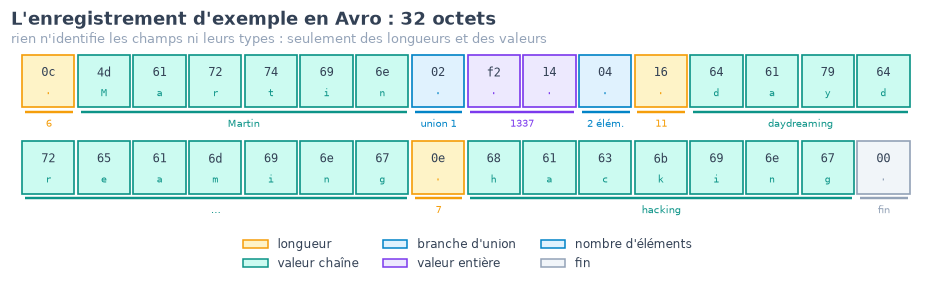

In [3]:
trace = []
av = E.avro_encode(R, W, trace)
fig = E.draw_byte_map(av, trace, title=f"L'enregistrement d'exemple en Avro : {len(av)} octets", per_row=16,
                      subtitle_text="rien n'identifie les champs ni leurs types : seulement des longueurs et des valeurs")
E.byte_legend(fig.axes[0], ["length", "str", "union", "int", "count", "end"], loc="upper center",
              bbox_to_anchor=(0.5, 0.0), ncol=3)
plt.tight_layout(); plt.show()

32 octets, le plus compact de tous. Une chaîne est une longueur (varint zigzag : `0c` =
6) suivie des octets UTF-8 ; l'union commence par l'indice de sa branche (`02` = branche
1, `long`) ; un tableau est une suite de blocs (`04` = 2 éléments, puis `00` = fin).
Mais **rien** ne dit que `0c` est une longueur de chaîne plutôt qu'un entier : pour
décoder, il faut parcourir les champs **dans l'ordre du schéma** et lire chacun selon son
type. Conséquence : il faut exactement le schéma avec lequel la donnée a été écrite.
Essayons de décoder ces 32 octets avec un autre schéma, où l'ordre des champs diffère.

In [4]:
autre_ordre = {"type": "record", "name": "Person", "fields": [W["fields"][1], W["fields"][0], W["fields"][2]]}
try:
    print(E.avro_decode(av, autre_ordre))
except E.AvroError as exc:
    print("échec :", exc)
entiers = {"type": "record", "name": "Person", "fields": [{"name": "a", "type": "long"}, {"name": "b", "type": "long"},
                                                         {"name": "c", "type": "long"}]}
try:
    print("lu comme trois entiers :", E.avro_decode(av[:3], entiers))
except E.AvroError as exc:
    print("échec :", exc)

échec : indice de branche 6 hors de l'union de l'écrivain
lu comme trois entiers : {'a': 6, 'b': -39, 'c': -49}


Avec le mauvais schéma, on obtient au mieux une erreur, au pire des valeurs absurdes
(les trois premiers octets « lus comme des entiers » donnent 6, -39 et -49 : la longueur
de `Martin` puis ses deux premières lettres, décodées en zigzag). Avro tranche ce problème en exigeant que le
lecteur **connaisse le schéma de l'écrivain**.

> **À retenir.** L'encodage Avro n'est qu'une concaténation de valeurs (varints zigzag,
> chaînes préfixées par leur longueur, indices de branche d'union) : 32 octets pour
> l'exemple. Sans le schéma exact de l'écrivain, les octets sont indéchiffrables.

## 2. Schéma de l'écrivain, schéma du lecteur (section *The writer's schema and the reader's schema*)

Une application qui **encode** utilise la version du schéma qu'elle connaît (souvent
compilée dans son code) : c'est le **schéma de l'écrivain**. Une application qui
**décode** utilise deux schémas : celui de l'écrivain (pour savoir comment lire les
octets) et le **sien**, le **schéma du lecteur**, qui décrit les champs et les types que
son code attend. Les deux n'ont pas besoin d'être identiques, seulement **compatibles**.
La bibliothèque Avro **résout** les différences :

- les champs sont appariés **par nom**, l'ordre peut différer ;
- un champ présent chez l'écrivain mais pas chez le lecteur est **ignoré** ;
- un champ attendu par le lecteur mais absent chez l'écrivain prend la **valeur par
  défaut** déclarée dans le schéma du lecteur.

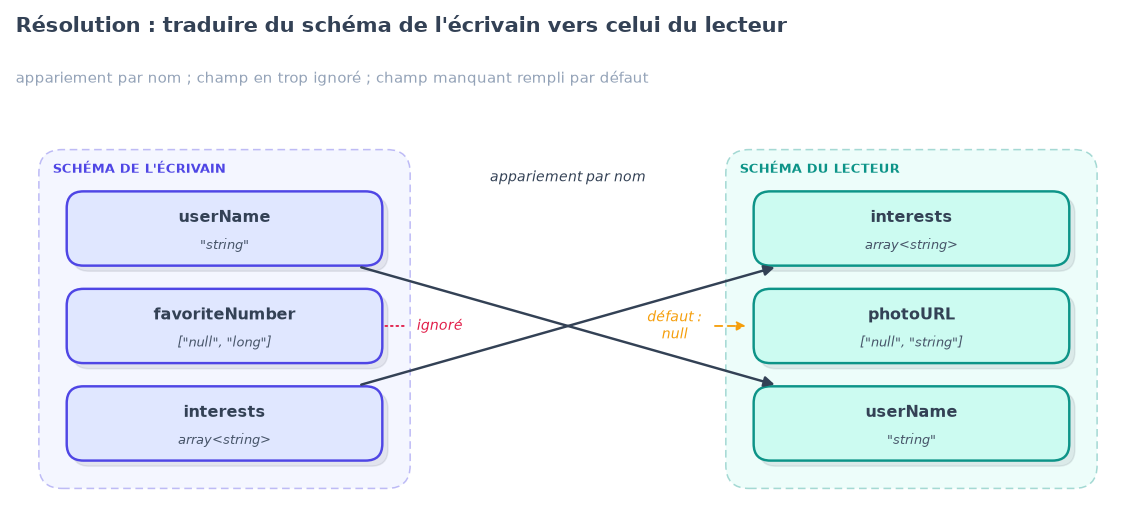

In [5]:
lecteur = {"type": "record", "name": "Person", "fields": [
    {"name": "interests", "type": {"type": "array", "items": "string"}},
    {"name": "photoURL", "type": ["null", "string"], "default": None},
    {"name": "userName", "type": "string"},
]}
d = Diagram(12, 4.4, title="Résolution : traduire du schéma de l'écrivain vers celui du lecteur",
            subtitle="appariement par nom ; champ en trop ignoré ; champ manquant rempli par défaut")
d.group(0.3, 0.2, 4.3, 3.85, "schéma de l'écrivain", color=INDIGO)
d.group(7.7, 0.2, 11.7, 3.85, "schéma du lecteur", color=TEAL)
for i, f in enumerate(W["fields"]):
    d.box(f"w{i}", 2.3, 3.0 - i * 1.05, f["name"], sub=json.dumps(f["type"]) if i < 2 else "array<string>", color=INDIGO, w=3.4, h=0.8)
for i, f in enumerate(lecteur["fields"]):
    d.box(f"r{i}", 9.7, 3.0 - i * 1.05, f["name"], sub="array<string>" if i == 0 else json.dumps(f["type"]), color=TEAL, w=3.4, h=0.8)
d.arrow("w0", "r2", color=SLATE)
d.arrow("w2", "r0", color=SLATE)
d.note(6.0, 3.55, "appariement par nom", color=SLATE)
d.line([(4.0, 1.95), (4.3, 1.95)], color=ROSE, style="dotted", arrow=False)
d.note(4.62, 1.95, "ignoré", color=ROSE)
d.note(7.15, 1.95, "défaut :\nnull", color=AMBER)
d.line([(7.55, 1.95), (7.95, 1.95)], color=AMBER, style="dashed")
d.show()

In [6]:
print("écrit avec l'écrivain :", R)
print("lu par le lecteur     :", E.avro_decode(av, W, lecteur))

écrit avec l'écrivain : {'userName': 'Martin', 'favoriteNumber': 1337, 'interests': ['daydreaming', 'hacking']}
lu par le lecteur     : {'interests': ['daydreaming', 'hacking'], 'photoURL': None, 'userName': 'Martin'}


Le lecteur obtient ses champs dans **son** ordre, `favoriteNumber` a disparu (ignoré),
`photoURL` vaut `None` (défaut). À comparer avec Protocol Buffers (cours 2) : là-bas un
seul schéma suffit au décodage, car chaque champ porte son numéro et son type d'onde ;
ici, l'information est déplacée des données vers le schéma de l'écrivain, qui doit
voyager d'une manière ou d'une autre jusqu'au lecteur (section 4).

> **À retenir.** Avro décode avec deux schémas : celui de l'écrivain, pour lire les
> octets, et celui du lecteur, pour produire ce que le code attend. La résolution
> apparie les champs par nom, ignore les champs en trop et complète les manquants avec
> les valeurs par défaut du lecteur.

## 3. Les règles d'évolution (section *Schema evolution rules*)

Avec Avro, **compatibilité ascendante** signifie qu'un écrivain peut avoir un schéma plus
récent que le lecteur ; **descendante**, que l'écrivain peut avoir un schéma plus ancien.
Les règles découlent directement de la résolution :

- on ne peut ajouter ou supprimer **que des champs qui ont une valeur par défaut**.
  Ajouter un champ sans défaut : un nouveau lecteur ne sait pas quoi mettre dans les
  anciennes données (descendante cassée). Supprimer un champ sans défaut : un ancien
  lecteur l'exige et ne le trouve pas (ascendante cassée) ;
- `null` n'est pas une valeur acceptable pour n'importe quel type : il faut une
  **union** (`["null", "long"]`), et `null` ne peut servir de défaut que s'il est la
  **première** branche. Plus verbeux que « tout est nullable », mais explicite, ce qui
  évite une classe entière de bogues ;
- changer le **type** d'un champ est possible si Avro sait convertir (`int` vers `long`,
  `float` ou `double`, `string` vers `bytes`...) ;
- **renommer** un champ passe par des **alias** dans le schéma du lecteur : compatible
  en descendante (le nouveau lecteur reconnaît l'ancien nom), pas en ascendante ;
- **ajouter une branche à une union** : compatible en descendante seulement.

Le module fournit une vérification statique (`E.avro_compatible(écrivain, lecteur)`), qui
parcourt les deux schémas comme le ferait la résolution. Testons une batterie
d'évolutions de v1 (`Person`), dans les deux sens, et confirmons chaque verdict en
décodant réellement des données.

In [7]:
def v1_avec(*, add=None, drop=None, replace=None):
    """Variante du schéma v1 : ajout d'un champ, suppression, ou remplacement (ancien nom, nouveau champ)."""
    s = copy.deepcopy(W)
    if drop:
        s["fields"] = [f for f in s["fields"] if f["name"] != drop]
    if replace:
        ancien_nom, nouveau = replace
        s["fields"] = [nouveau if f["name"] == ancien_nom else f for f in s["fields"]]
    if add:
        s["fields"].append(add)
    return s

FN = "favoriteNumber"
evolutions = {
    "ajouter un champ avec défaut": v1_avec(add={"name": "photoURL", "type": ["null", "string"], "default": None}),
    "ajouter un champ sans défaut": v1_avec(add={"name": "photoURL", "type": "string"}),
    "supprimer un champ avec défaut": v1_avec(drop=FN),
    "supprimer un champ sans défaut": v1_avec(drop="userName"),
    "renommer (alias chez le lecteur)": v1_avec(replace=("userName", {"name": "name", "aliases": ["userName"], "type": "string"})),
    "long -> double (promotion)": v1_avec(replace=(FN, {"name": FN, "type": ["null", "double"], "default": None})),
    "long -> string": v1_avec(replace=(FN, {"name": FN, "type": ["null", "string"], "default": None})),
    "ajouter une branche d'union": v1_avec(replace=(FN, {"name": FN, "type": ["null", "long", "string"], "default": None})),
}

def adapte(r, writer):
    """L'enregistrement r tel que l'écrirait une application qui utilise le schéma `writer`."""
    out = {}
    for f in writer["fields"]:
        types = f["type"] if isinstance(f["type"], list) else [f["type"]]
        nom = f["name"]
        v = r.get(nom, r["userName"] if nom == "name" else ("p.jpg" if nom == "photoURL" else None))
        if nom == FN and v is not None and "long" not in types:
            v = float(v) if "double" in types else str(v)
        out[nom] = v
    return out

def essai(writer, reader, n=200):
    """Décode réellement n enregistrements écrits avec `writer` en utilisant `reader`."""
    try:
        for r in E.make_people(n, seed=7):
            E.avro_decode(E.avro_encode(adapte(r, writer), writer), writer, reader)
    except E.AvroError:
        return False
    return True

rows = []
for nom, v2 in evolutions.items():
    desc, _ = E.avro_compatible(W, v2)          # écrivain v1, lecteur v2
    asc, _ = E.avro_compatible(v2, W)           # écrivain v2, lecteur v1
    rows.append({"évolution": nom, "descendante (statique)": desc, "descendante (données)": essai(W, v2),
                 "ascendante (statique)": asc, "ascendante (données)": essai(v2, W)})
mat = pd.DataFrame(rows).set_index("évolution")
mat

,descendante (statique),descendante (données),ascendante (statique),ascendante (données)
évolution,,,,
ajouter un champ avec défaut,True,True,True,True
ajouter un champ sans défaut,False,False,True,True
supprimer un champ avec défaut,True,True,True,True
supprimer un champ sans défaut,True,True,False,False
renommer (alias chez le lecteur),True,True,False,False
long -> double (promotion),True,True,False,False
long -> string,False,False,False,False
ajouter une branche d'union,True,True,False,True


Les colonnes « statique » (analyse des schémas) et « données » (décodage réel de 200
enregistrements) concordent, à une exception instructive près : **ajouter une branche
d'union** est déclaré incompatible en ascendante par l'analyse statique, alors que nos
données passent. C'est que notre générateur n'a écrit aucun `favoriteNumber` de type
chaîne : la nouvelle branche n'a jamais servi. Le jour où un écrivain v2 l'utilise, un
lecteur v1 échoue. Tester sur des données ne prouve rien sur les cas absents ; l'analyse
des schémas, si.

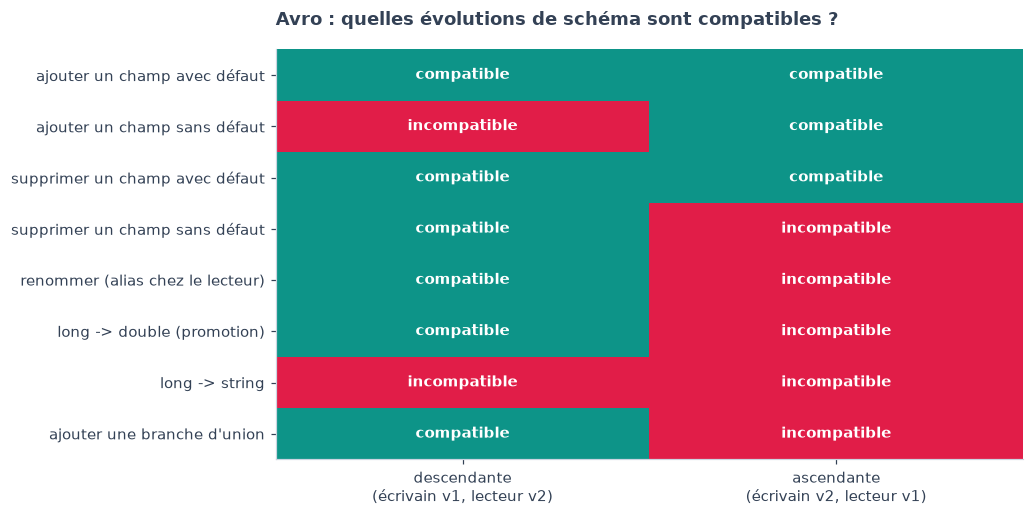

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
vals = mat[["descendante (statique)", "ascendante (statique)"]].values.astype(float)
ax.imshow(vals, cmap="ddia_div", vmin=0, vmax=1, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(2):
        ax.text(j, i, "compatible" if vals[i, j] else "incompatible", ha="center", va="center", color="white",
                fontweight="bold", fontsize=9.5)
ax.set_xticks([0, 1], ["descendante\n(écrivain v1, lecteur v2)", "ascendante\n(écrivain v2, lecteur v1)"])
ax.set_yticks(range(len(mat)), mat.index)
ax.grid(False)
ax.set_title("Avro : quelles évolutions de schéma sont compatibles ?")
plt.tight_layout(); plt.show()

Seuls l'ajout et la suppression de champs **avec défaut** sont compatibles dans les deux
sens (on parle de compatibilité **totale**, « full »). Le renommage, la promotion de type
et l'ajout de branche ne marchent que dans un sens ; `long -> string` dans aucun.

> **À retenir.** En Avro, ajouter ou supprimer un champ n'est compatible dans les deux
> sens que s'il a une valeur par défaut ; `null` passe par une union dont il est la
> première branche ; alias, promotions et nouvelles branches d'union ne sont compatibles
> qu'en descendante.